In [48]:
!mkdir -p ../figures ../data

# Mini Project Machine Learning untuk Biologi
## Membedakan Tiga Kultivar Anggur (*Vitis vinifera*) Berdasarkan Profil Kimia

**Mata kuliah:** Data Sains  |  **Dataset:** Wine (`sklearn.datasets.load_wine`)  |  **Kelompok:** *(isi nama kelompok & anggota)*

**Alur notebook:** Tahap 1 Pendefinisian masalah → 2 EDA → 3 Preprocessing → 4 Supervised → 5 Unsupervised → 6 Interpretasi → 7 Diskusi & keterbatasan.

> Notebook ini dapat dijalankan dari awal sampai akhir (*Restart & Run All*). Semua `random_state` ditetapkan = 42 agar hasil dapat direproduksi.

## Tahap 1 - Pendefinisian Masalah

**Pertanyaan biologis.** Apakah profil kimia anggur (13 variabel hasil analisis kimia) cukup untuk membedakan tiga kultivar anggur yang ditanam di wilayah yang sama, dan variabel kimia apa yang paling membedakan kultivar-kultivar tersebut?

**Mengapa penting.** Kultivar menentukan komposisi senyawa fenolik, asam, dan gula dalam buah anggur, sehingga memengaruhi warna, rasa, dan kualitas anggur. Penentuan asal-kultivar berbasis kimia berguna untuk **autentikasi dan kontrol mutu** (mendeteksi pemalsuan/pencampuran), serta membantu memahami **kemotaksonomi** (ciri kimia khas tiap varietas).

**Jenis tugas.**
- *Supervised:* klasifikasi multikelas (3 kultivar).
- *Unsupervised:* reduksi dimensi (PCA) dan klasterisasi (K-Means, pembanding: hierarchical Ward) tanpa memakai label, lalu dibandingkan dengan label asli.

**Metrik evaluasi utama: F1-score (macro)**, dilengkapi accuracy, precision, recall, confusion matrix, dan ROC-AUC (One-vs-Rest).
Alasan: kelas tidak sepenuhnya seimbang (59 / 71 / 48), sehingga accuracy saja dapat menyesatkan. F1 macro memberi bobot sama pada setiap kultivar sehingga kesalahan pada kultivar yang lebih kecil tetap terlihat. Untuk klasterisasi dipakai *silhouette* (kualitas klaster internal) serta *Adjusted Rand Index* (ARI) dan *NMI* (kecocokan dengan label asli).

In [49]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import (train_test_split, cross_validate, StratifiedKFold,
                                     GridSearchCV, permutation_test_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, roc_curve, auc,
                             roc_auc_score, accuracy_score, silhouette_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import dendrogram, linkage

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
print("Library berhasil dimuat.")

Library berhasil dimuat.


## Tahap 2 - Exploratory Data Analysis (EDA)

Memuat data, menyimpan salinannya ke `data/wine.csv`, lalu memeriksa ukuran, tipe, *missing value*, dan proporsi kelas.

In [50]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()
fitur = list(wine.feature_names)
df["kultivar"] = df["target"].map({0: "Kultivar 0", 1: "Kultivar 1", 2: "Kultivar 2"})

X = df[fitur]
y = df["target"]
nama_kelas = ["Kultivar 0", "Kultivar 1", "Kultivar 2"]

# simpan salinan data mentah ke folder data/ (untuk repositori)
import os
os.makedirs("../data", exist_ok=True)
df.drop(columns="kultivar").to_csv("../data/wine.csv", index=False)

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,kultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,Kultivar 0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,Kultivar 0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,Kultivar 0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,Kultivar 0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,Kultivar 0


In [51]:
print("Ukuran data (baris, kolom):", X.shape)
print("\nTipe data fitur:")
print(X.dtypes.value_counts())
print("\nTotal missing value:", int(X.isna().sum().sum()))
print("Duplikat baris     :", int(df.duplicated().sum()))
print("\nProporsi kelas:")
print(pd.DataFrame({"jumlah": y.value_counts().sort_index(),
                    "proporsi (%)": (y.value_counts(normalize=True).sort_index()*100).round(1)}))

Ukuran data (baris, kolom): (178, 13)

Tipe data fitur:
float64    13
Name: count, dtype: int64

Total missing value: 0
Duplikat baris     : 0

Proporsi kelas:
        jumlah  proporsi (%)
target                      
0           59          33.1
1           71          39.9
2           48          27.0


**Temuan awal.** Data berisi **178 sampel × 13 fitur numerik** (semua `float64`), **tanpa missing value dan tanpa duplikat**. Proporsi kelas 33,1% / 39,9% / 27,0% - sedikit tidak seimbang, jadi pemisahan data harus berstrata dan metrik macro lebih tepat.

In [52]:
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


Skala antarfitur sangat berbeda (mis. `proline` ratusan-ribuan, `hue` sekitar 1). Maka **standardisasi wajib** untuk SVM, Logistic Regression, PCA, dan K-Means.

### Visualisasi 1 - Proporsi kelas

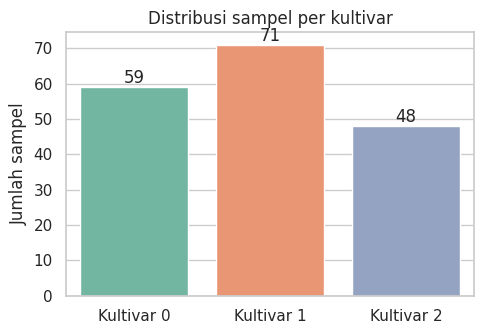

In [53]:
# Visualisasi 1: proporsi kelas
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x="kultivar", data=df, order=nama_kelas, palette="Set2", ax=ax)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Distribusi sampel per kultivar")
ax.set_xlabel(""); ax.set_ylabel("Jumlah sampel")
plt.tight_layout(); plt.savefig("../figures/01_proporsi_kelas.png", dpi=150); plt.show()

### Visualisasi 2 - Distribusi fitur per kultivar

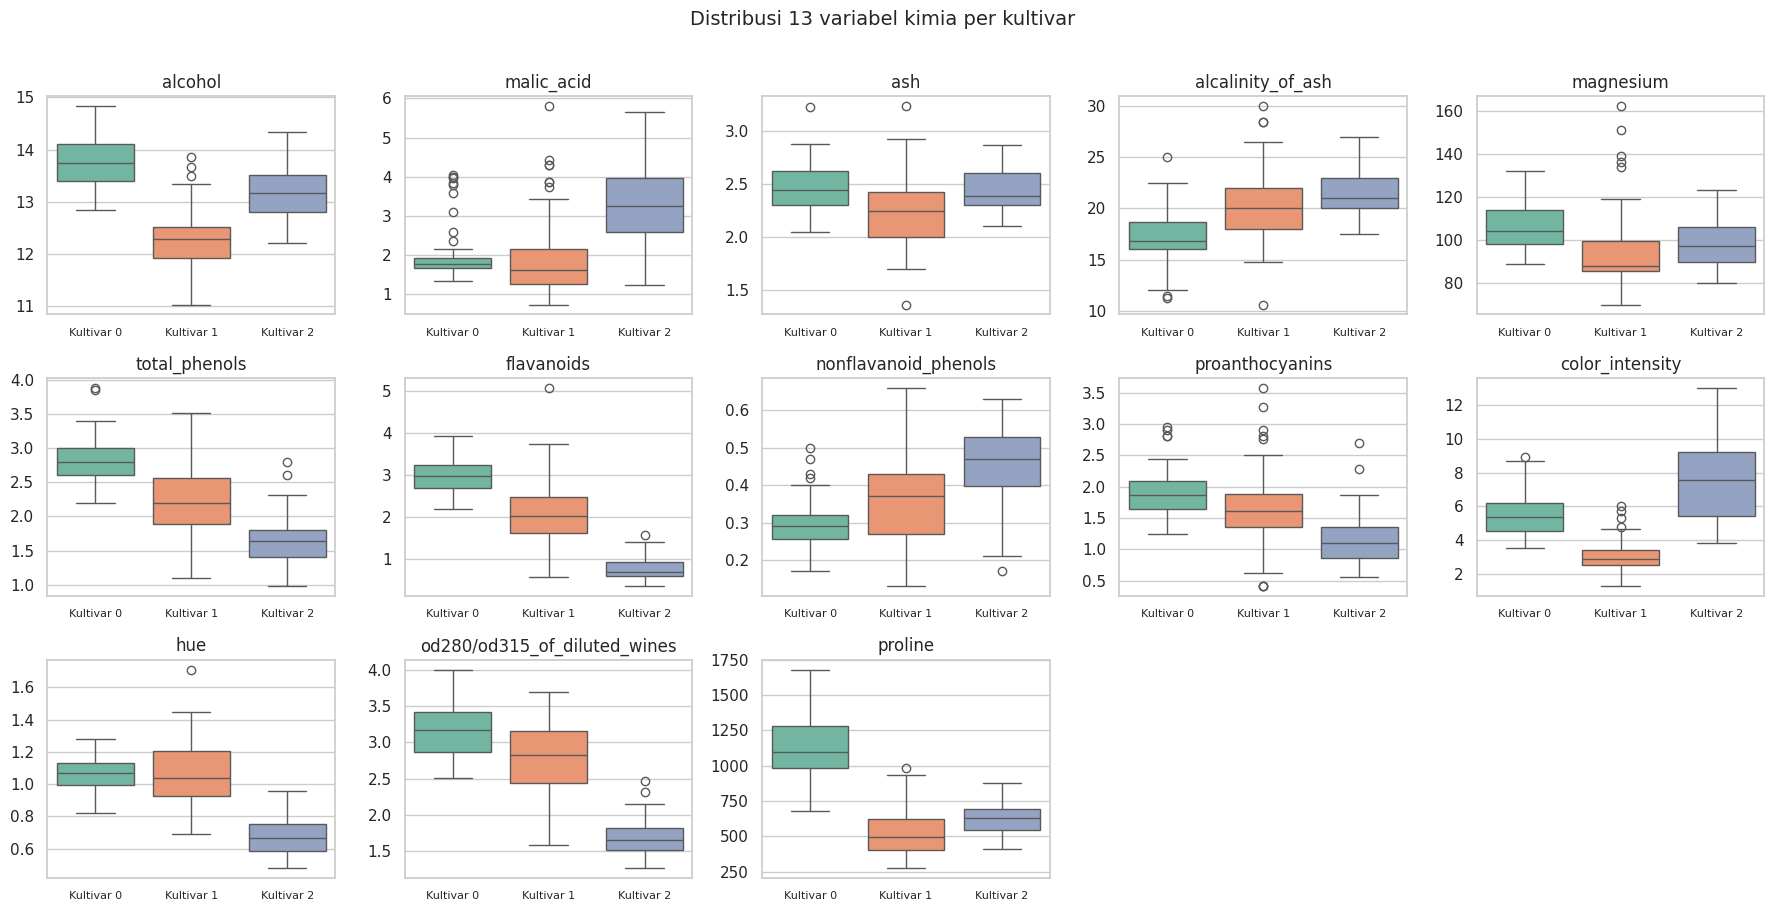

In [54]:
# Visualisasi 2: distribusi tiap fitur per kultivar
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, f in zip(axes.ravel(), fitur):
    sns.boxplot(x="kultivar", y=f, data=df, order=nama_kelas, palette="Set2", ax=ax)
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=8)
for ax in axes.ravel()[len(fitur):]:
    ax.axis("off")
plt.suptitle("Distribusi 13 variabel kimia per kultivar", y=1.01, fontsize=14)
plt.tight_layout(); plt.savefig("../figures/02_boxplot_fitur.png", dpi=150, bbox_inches="tight"); plt.show()

**Pengamatan.** `flavanoids`, `total_phenols`, `od280/od315`, `proline`, `color_intensity`, dan `alcohol` tampak memisahkan kultivar dengan jelas. Contoh: Kultivar 0 memiliki `proline` tertinggi, Kultivar 2 memiliki `flavanoids` terendah dan `color_intensity` tertinggi, sedangkan Kultivar 1 cenderung rendah pada `alcohol` dan `color_intensity`.

### Visualisasi 3 - Korelasi antar fitur

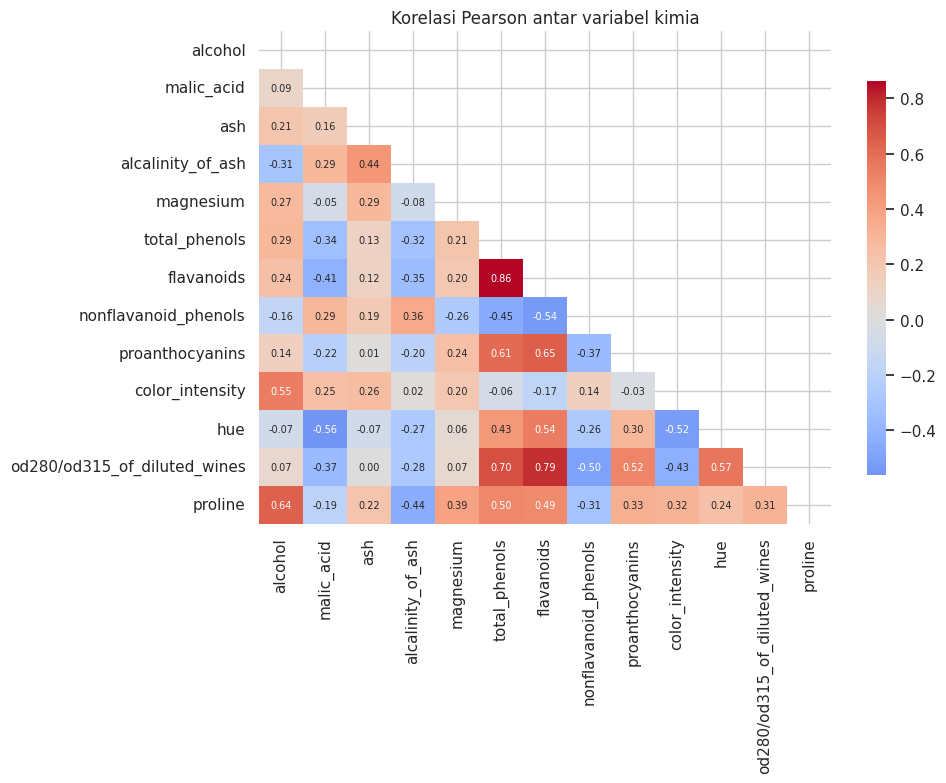

5 pasangan fitur dengan korelasi terkuat:
                     level_0       level_1    r
                  flavanoids total_phenols 0.86
od280/od315_of_diluted_wines    flavanoids 0.79
od280/od315_of_diluted_wines total_phenols 0.70
             proanthocyanins    flavanoids 0.65
                     proline       alcohol 0.64


In [55]:
# Visualisasi 3: heatmap korelasi antar fitur
fig, ax = plt.subplots(figsize=(10, 8))
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 7}, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Korelasi Pearson antar variabel kimia")
plt.tight_layout(); plt.savefig("../figures/03_korelasi.png", dpi=150); plt.show()

pasangan = (corr.where(~mask).stack().rename("r").reset_index()
            .assign(abs_r=lambda d: d.r.abs()).sort_values("abs_r", ascending=False).head(5))
print("5 pasangan fitur dengan korelasi terkuat:")
print(pasangan[["level_0", "level_1", "r"]].round(2).to_string(index=False))

**Pengamatan.** Beberapa fitur berkorelasi kuat (`flavanoids`-`total_phenols` r = 0,86; `od280/od315`-`flavanoids` r = 0,79). Ini wajar karena semuanya terkait senyawa fenolik. Konsekuensinya: **multikolinearitas** → koefisien Logistic Regression dan feature importance perlu ditafsirkan hati-hati, dan PC1 pada PCA akan didominasi kelompok fenolik.

### Visualisasi 4 - Pairplot fitur terpilih

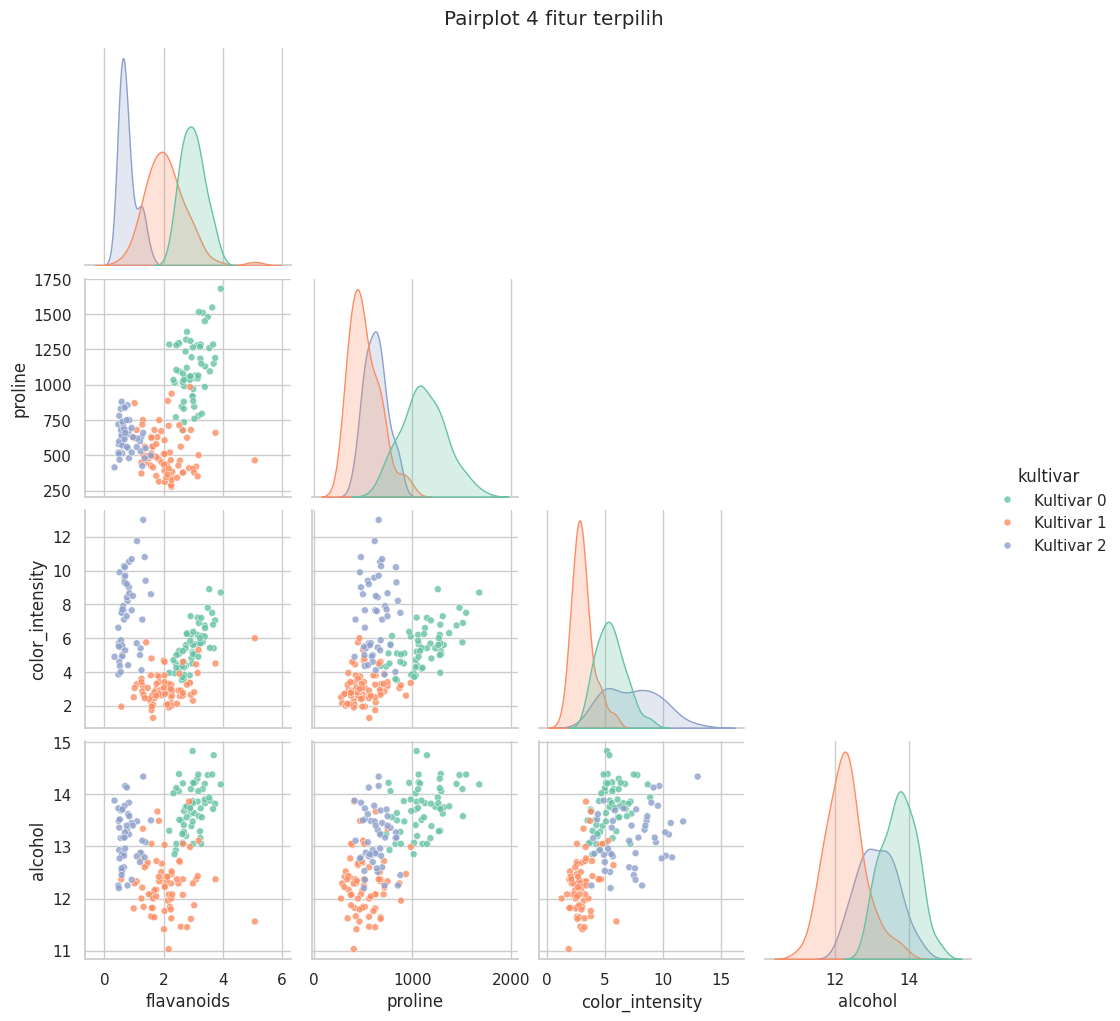

In [56]:
# Visualisasi 4: pairplot 4 fitur yang tampak paling membedakan kultivar
fitur_pilihan = ["flavanoids", "proline", "color_intensity", "alcohol"]
g = sns.pairplot(df, vars=fitur_pilihan, hue="kultivar", palette="Set2",
                 hue_order=nama_kelas, corner=True, plot_kws={"s": 25, "alpha": .8})
g.fig.suptitle("Pairplot 4 fitur terpilih", y=1.02)
g.savefig("../figures/04_pairplot.png", dpi=150); plt.show()

## Tahap 3 - Preprocessing

- **Imputasi:** tidak diperlukan (tidak ada *missing value*), tetapi bila ada, `SimpleImputer` akan dimasukkan ke dalam Pipeline.
- **Encoding:** tidak diperlukan (semua fitur numerik, target sudah berupa 0/1/2).
- **Scaling:** `StandardScaler` **di dalam `Pipeline`**, sehingga rata-rata & simpangan baku dihitung hanya dari data latih pada tiap fold → **tidak ada data leakage**.
- **Split:** 80% latih / 20% uji dengan `stratify=y`. Data uji tidak disentuh sampai evaluasi akhir.

In [57]:
# Split train/test 80:20 dengan stratify (proporsi kelas dijaga)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nProporsi kelas train:", (y_train.value_counts(normalize=True).sort_index().round(3)).tolist())
print("Proporsi kelas test :", (y_test.value_counts(normalize=True).sort_index().round(3)).tolist())

Train: (142, 13) | Test: (36, 13)

Proporsi kelas train: [0.331, 0.401, 0.268]
Proporsi kelas test : [0.333, 0.389, 0.278]


## Tahap 4 - Supervised Learning

### 4.1 Perbandingan model dengan Stratified 5-fold Cross-Validation
Model: **Baseline** (`DummyClassifier`, selalu menebak kelas mayoritas), **Logistic Regression**, **Random Forest**, dan **SVM (RBF)**. Hasil dilaporkan sebagai rata-rata ± simpangan baku pada data latih.

In [58]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Scaler dimasukkan ke dalam Pipeline -> di-fit hanya pada fold training (tanpa data leakage)
models = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(probability=True, random_state=RANDOM_STATE)),
}

hasil_cv = []
for nama, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv,
                       scoring=["accuracy", "f1_macro", "precision_macro", "recall_macro"])
    hasil_cv.append({
        "Model": nama,
        "Accuracy": f"{s['test_accuracy'].mean():.3f} ± {s['test_accuracy'].std():.3f}",
        "Precision (macro)": f"{s['test_precision_macro'].mean():.3f} ± {s['test_precision_macro'].std():.3f}",
        "Recall (macro)": f"{s['test_recall_macro'].mean():.3f} ± {s['test_recall_macro'].std():.3f}",
        "F1 (macro)": f"{s['test_f1_macro'].mean():.3f} ± {s['test_f1_macro'].std():.3f}",
        "_f1_mean": s["test_f1_macro"].mean(),
    })
tabel_cv = pd.DataFrame(hasil_cv).sort_values("_f1_mean", ascending=False)
model_terbaik = tabel_cv.iloc[0]["Model"]
print(f"Model terbaik berdasarkan rata-rata F1 macro CV: {model_terbaik}\n")
tabel_cv.drop(columns="_f1_mean").reset_index(drop=True)

Model terbaik berdasarkan rata-rata F1 macro CV: SVM (RBF)



,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,SVM (RBF),0.986 ± 0.017,0.987 ± 0.017,0.988 ± 0.015,0.986 ± 0.017
1,Logistic Regression,0.979 ± 0.028,0.979 ± 0.029,0.983 ± 0.022,0.980 ± 0.027
2,Random Forest,0.979 ± 0.028,0.979 ± 0.029,0.983 ± 0.022,0.979 ± 0.029
3,Baseline (Dummy),0.401 ± 0.010,0.134 ± 0.003,0.333 ± 0.000,0.191 ± 0.003


**Interpretasi.** Baseline hanya mencapai akurasi ≈ 0,40 (setara proporsi kelas mayoritas), sehingga ketiga model sungguhan jauh lebih baik dari tebakan. SVM (RBF) sedikit unggul (F1 macro 0,986), tetapi **selisih antar-model (0,979-0,986) lebih kecil daripada simpangan bakunya (≈ 0,02-0,03)**, jadi ketiganya secara praktis setara. Model sederhana (Logistic Regression) hampir sama baiknya dengan model yang lebih kompleks.

### 4.2 Hyperparameter tuning (GridSearchCV) pada model terbaik

In [59]:
# Hyperparameter tuning pada model terbaik (hanya data train, 5-fold CV)
param_grids = {
    "Logistic Regression": {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
    "SVM (RBF)": {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.05, 0.1],
                  "svc__kernel": ["linear", "rbf"]},
    "Random Forest": {"max_depth": [None, 3, 5, 10], "n_estimators": [100, 300],
                      "min_samples_leaf": [1, 2, 4]},
}
gs = GridSearchCV(models[model_terbaik], param_grids[model_terbaik], cv=cv,
                  scoring="f1_macro", n_jobs=-1)
gs.fit(X_train, y_train)
print("Model dituning :", model_terbaik)
print("Parameter terbaik:", gs.best_params_)
print(f"F1 macro CV terbaik: {gs.best_score_:.3f}")
best_model = gs.best_estimator_

Model dituning : SVM (RBF)
Parameter terbaik: {'svc__C': 100, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
F1 macro CV terbaik: 0.994


### 4.3 Evaluasi akhir pada data uji (satu kali)

Accuracy test: 0.972

              precision    recall  f1-score   support

  Kultivar 0      1.000     1.000     1.000        12
  Kultivar 1      0.933     1.000     0.966        14
  Kultivar 2      1.000     0.900     0.947        10

    accuracy                          0.972        36
   macro avg      0.978     0.967     0.971        36
weighted avg      0.974     0.972     0.972        36



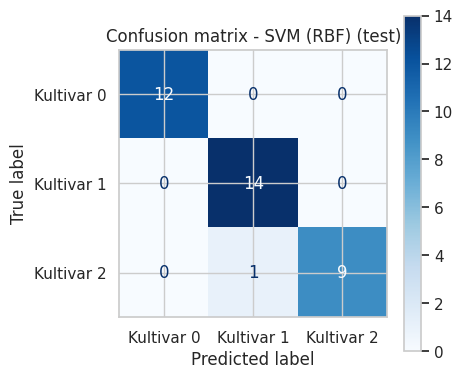

In [60]:
# Evaluasi akhir pada data test (dilakukan SEKALI saja)
y_pred = best_model.predict(X_test)
print(f"Accuracy test: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, target_names=nama_kelas, digits=3))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=nama_kelas, cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix - {model_terbaik} (test)")
plt.tight_layout(); plt.savefig("../figures/05_confusion_matrix.png", dpi=150); plt.show()

**Interpretasi.** Pada 36 sampel uji, model benar 35 (akurasi 0,972). Satu-satunya kesalahan: satu sampel Kultivar 2 diprediksi sebagai Kultivar 1. Kultivar 0 terklasifikasi sempurna. Karena data uji kecil, **satu kesalahan = 2,8 poin persentase**, sehingga angka ini sebaiknya dibaca bersama hasil CV.

### 4.4 Kurva ROC (One-vs-Rest)

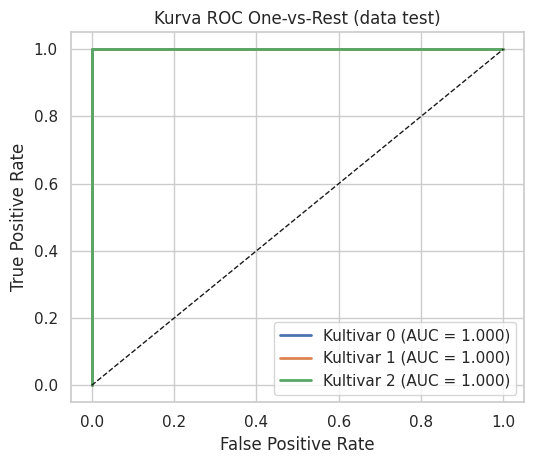

AUC macro OvR: 1.0


In [61]:
# ROC One-vs-Rest untuk 3 kelas
if hasattr(best_model, "predict_proba"):
    proba = best_model.predict_proba(X_test)
else:  # fallback jika model tidak punya predict_proba
    proba = best_model.decision_function(X_test)
y_bin = label_binarize(y_test, classes=[0, 1, 2])

fig, ax = plt.subplots(figsize=(5.5, 4.8))
for i, nm in enumerate(nama_kelas):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    ax.plot(fpr, tpr, lw=2, label=f"{nm} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("Kurva ROC One-vs-Rest (data test)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("../figures/06_roc.png", dpi=150); plt.show()
print("AUC macro OvR:", round(roc_auc_score(y_test, proba, multi_class="ovr", average="macro"), 3))

AUC mendekati 1,0 untuk ketiga kelas: model menghasilkan peringkat probabilitas yang hampir sempurna memisahkan tiap kultivar dari dua lainnya.

### 4.5 Pemeriksaan data leakage / overfitting
Tips dosen: hasil mendekati sempurna patut dicurigai. Pemeriksaan yang dilakukan: (1) scaler berada di dalam Pipeline; (2) data uji tidak dipakai untuk memilih model/hiperparameter; (3) **permutation test** - label diacak, performa harus runtuh ke tebakan acak; (4) **repeated CV** pada seluruh data untuk estimasi yang lebih stabil.

In [62]:
# Cek kewajaran: apakah akurasi tinggi karena data leakage / kebetulan?
# Permutation test: label diacak berkali-kali -> performa harus jatuh ke ~33% (tebakan acak)
skor, skor_acak, pval = permutation_test_score(
    best_model, X_train, y_train, cv=cv, scoring="accuracy",
    n_permutations=100, random_state=RANDOM_STATE, n_jobs=-1)
print(f"Akurasi CV (label asli)      : {skor:.3f}")
print(f"Akurasi CV (label diacak)    : {skor_acak.mean():.3f} ± {skor_acak.std():.3f}")
print(f"p-value permutation test     : {pval:.4f}")

# Pembanding: performa berulang dengan banyak split acak (stabilitas estimasi)
from sklearn.model_selection import RepeatedStratifiedKFold
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
s = cross_validate(best_model, X, y, cv=rcv, scoring="accuracy")
print(f"Accuracy 5x10 repeated CV (seluruh data): {s['test_score'].mean():.3f} ± {s['test_score'].std():.3f}")

Akurasi CV (label asli)      : 0.993
Akurasi CV (label diacak)    : 0.336 ± 0.045
p-value permutation test     : 0.0099
Accuracy 5x10 repeated CV (seluruh data): 0.966 ± 0.027


**Interpretasi.** Dengan label diacak, akurasi jatuh ke ≈ 0,34 (tebakan acak untuk 3 kelas), dengan p ≈ 0,01 (batas terendah untuk 100 permutasi), jadi performa tinggi berasal dari sinyal nyata pada fitur, bukan artefak. Skor CV hasil tuning (0,993-0,994) sedikit **optimistis** karena hiperparameter dipilih dari skor yang sama; estimasi yang lebih jujur adalah akurasi test 0,972 dan repeated CV ≈ 0,966 ± 0,027. Dataset Wine memang dikenal "mudah" karena kelas terpisah baik secara kimia.

## Tahap 5 - Unsupervised Learning

Label **tidak dipakai** selama PCA dan K-Means; label hanya dipakai di akhir untuk validasi. Data distandardisasi lebih dulu. (Karena label tidak terlibat, standardisasi pada seluruh data tidak menyebabkan kebocoran label.)

### 5.1 PCA

Variansi dijelaskan PC1 : 36.2%
Variansi dijelaskan PC2 : 19.2%
Kumulatif PC1+PC2       : 55.4%
Jumlah PC untuk >=80%   : 5 | untuk >=90%: 8


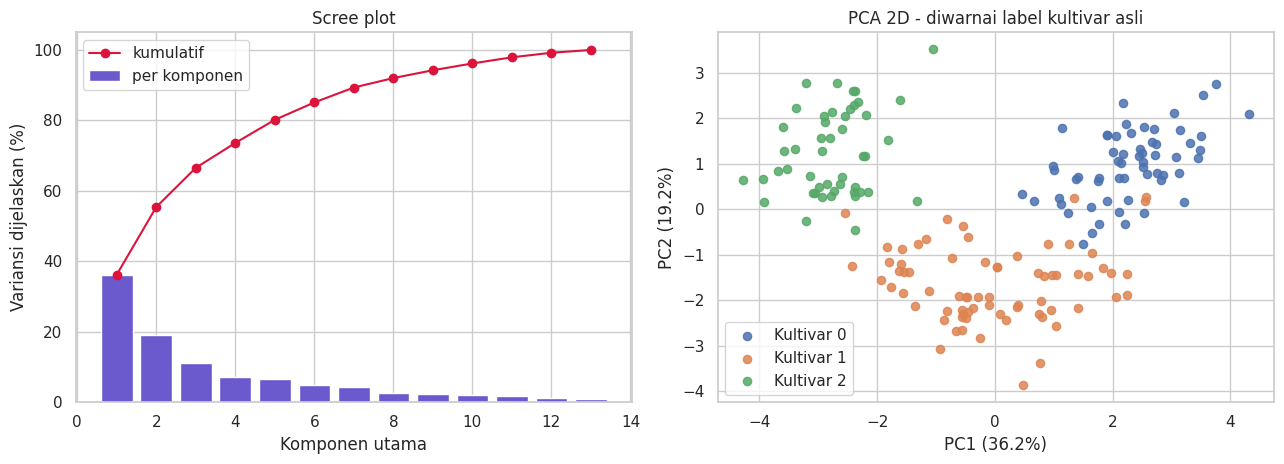


Loading terbesar:
PC1: ['flavanoids', 'total_phenols', 'od280/od315_of_diluted_wines', 'proanthocyanins']
PC2: ['color_intensity', 'alcohol', 'proline', 'ash']


,PC1,PC2
nonflavanoid_phenols,-0.299,0.029
malic_acid,-0.245,0.225
alcalinity_of_ash,-0.239,-0.011
color_intensity,-0.089,0.530
ash,-0.002,0.316
magnesium,0.142,0.300
alcohol,0.144,0.484
proline,0.287,0.365
hue,0.297,-0.279
proanthocyanins,0.313,0.039


In [63]:
# Unsupervised: standardisasi + PCA (label TIDAK dipakai)
Xs = StandardScaler().fit_transform(X)
pca_full = PCA(random_state=RANDOM_STATE).fit(Xs)
ev = pca_full.explained_variance_ratio_
cum = np.cumsum(ev)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
Xp = pca.fit_transform(Xs)
print("Variansi dijelaskan PC1 : %.1f%%" % (ev[0]*100))
print("Variansi dijelaskan PC2 : %.1f%%" % (ev[1]*100))
print("Kumulatif PC1+PC2       : %.1f%%" % (cum[1]*100))
print("Jumlah PC untuk >=80%%   : %d | untuk >=90%%: %d" % (np.argmax(cum>=.8)+1, np.argmax(cum>=.9)+1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].bar(range(1, 14), ev*100, color="slateblue", label="per komponen")
ax[0].plot(range(1, 14), cum*100, "o-", color="crimson", label="kumulatif")
ax[0].set_xlabel("Komponen utama"); ax[0].set_ylabel("Variansi dijelaskan (%)")
ax[0].set_title("Scree plot"); ax[0].legend()
for i, nm in enumerate(nama_kelas):
    ax[1].scatter(Xp[y==i, 0], Xp[y==i, 1], label=nm, s=35, alpha=.85)
ax[1].set_xlabel(f"PC1 ({ev[0]*100:.1f}%)"); ax[1].set_ylabel(f"PC2 ({ev[1]*100:.1f}%)")
ax[1].set_title("PCA 2D - diwarnai label kultivar asli"); ax[1].legend()
plt.tight_layout(); plt.savefig("../figures/09_pca.png", dpi=150); plt.show()

loadings = pd.DataFrame(pca.components_.T, index=fitur, columns=["PC1", "PC2"])
print("\nLoading terbesar:")
print("PC1:", loadings["PC1"].abs().sort_values(ascending=False).head(4).index.tolist())
print("PC2:", loadings["PC2"].abs().sort_values(ascending=False).head(4).index.tolist())
loadings.round(3).sort_values("PC1")

**Interpretasi.** PC1 menjelaskan 36,2% dan PC2 19,2% variansi (kumulatif **55,4%**); dibutuhkan 5 PC untuk ≥ 80% dan 8 PC untuk ≥ 90%. Artinya informasi tersebar di banyak dimensi, namun dua PC pertama sudah cukup memperlihatkan tiga kelompok yang hampir terpisah. **PC1** dibentuk terutama oleh `flavanoids`, `total_phenols`, `od280/od315`, `proanthocyanins` (kelompok fenolik); **PC2** oleh `color_intensity`, `alcohol`, `proline`, `ash`.

### 5.2 Menentukan jumlah klaster (elbow & silhouette)

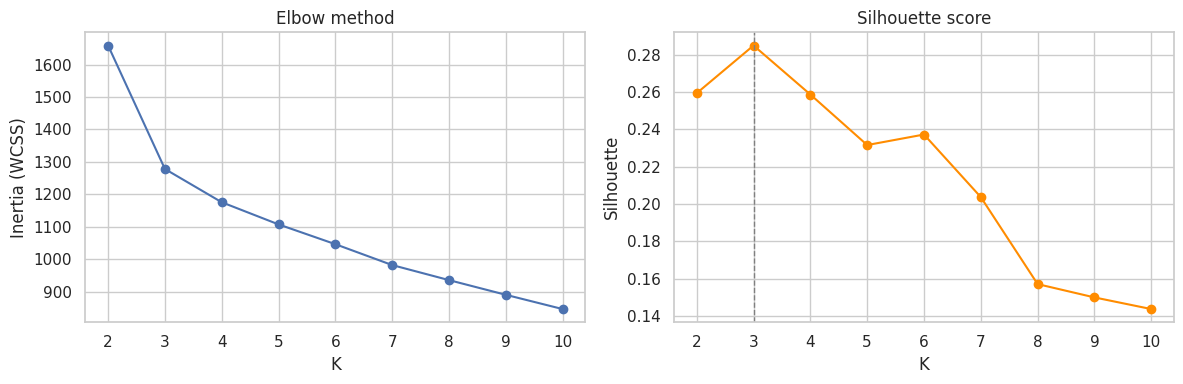

 K  inertia  silhouette
 2   1658.8       0.259
 3   1277.9       0.285
 4   1175.4       0.259
 5   1107.0       0.232
 6   1046.0       0.237
 7    981.6       0.204
 8    935.2       0.157
 9    889.9       0.150
10    845.9       0.144

K dengan silhouette tertinggi: 3


In [64]:
# Pemilihan jumlah klaster K: elbow (inertia) dan silhouette
Ks = range(2, 11)
inertia, sil = [], []
for k in Ks:
    km_k = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Xs)
    inertia.append(km_k.inertia_)
    sil.append(silhouette_score(Xs, km_k.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(Ks), inertia, "o-"); ax[0].set_title("Elbow method")
ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia (WCSS)")
ax[1].plot(list(Ks), sil, "o-", color="darkorange"); ax[1].set_title("Silhouette score")
ax[1].set_xlabel("K"); ax[1].set_ylabel("Silhouette")
ax[1].axvline(3, color="gray", ls="--", lw=1)
plt.tight_layout(); plt.savefig("../figures/10_elbow_silhouette.png", dpi=150); plt.show()
print(pd.DataFrame({"K": list(Ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)}).to_string(index=False))
print("\nK dengan silhouette tertinggi:", list(Ks)[int(np.argmax(sil))])

**Interpretasi.** Silhouette tertinggi pada **K = 3** (0,285) dan kurva inertia melandai setelah K = 3 (siku). Perlu dicatat nilai silhouette absolut tergolong rendah-sedang (< 0,5): klaster tidak sepenuhnya terpisah tajam dalam ruang 13 dimensi. K = 3 dipilih berdasarkan kedua kriteria tersebut (yang kebetulan juga cocok dengan jumlah kultivar).

### 5.3 K-Means (K = 3) dibandingkan label kultivar

Silhouette (K=3)            : 0.285
Adjusted Rand Index vs label: 0.897
Normalized Mutual Info      : 0.876

Tabel kontingensi (baris = kultivar asli, kolom = klaster K-Means):
klaster    0   1   2
kultivar            
0          0   0  59
1         65   3   3
2          0  48   0


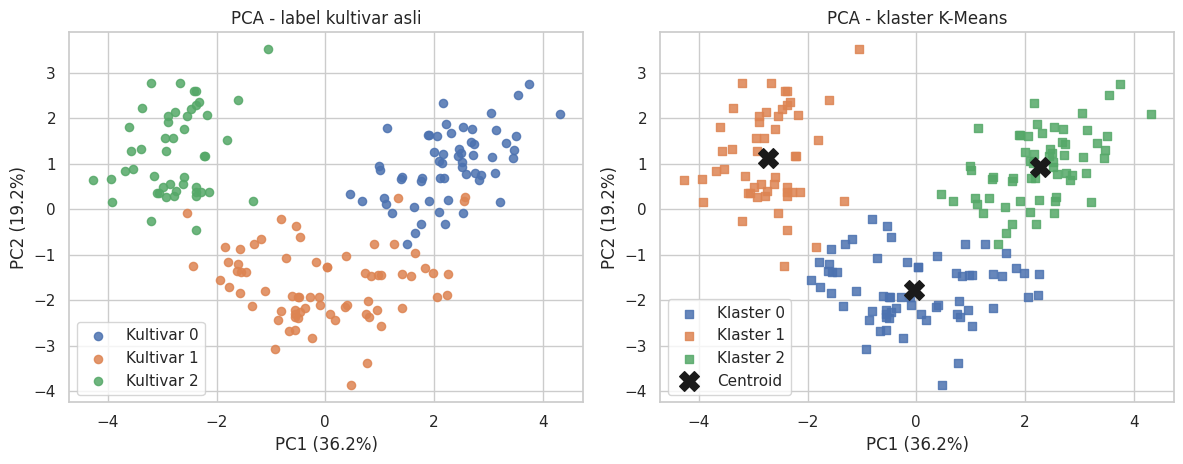

In [65]:
# K-Means dengan K = 3
km = KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE).fit(Xs)
lab = km.labels_
print(f"Silhouette (K=3)            : {silhouette_score(Xs, lab):.3f}")
print(f"Adjusted Rand Index vs label: {adjusted_rand_score(y, lab):.3f}")
print(f"Normalized Mutual Info      : {normalized_mutual_info_score(y, lab):.3f}")

print("\nTabel kontingensi (baris = kultivar asli, kolom = klaster K-Means):")
ct = pd.crosstab(pd.Series(y.values, name="kultivar"), pd.Series(lab, name="klaster"))
print(ct)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for i, nm in enumerate(nama_kelas):
    ax[0].scatter(Xp[y==i, 0], Xp[y==i, 1], label=nm, s=35, alpha=.85)
ax[0].set_title("PCA - label kultivar asli"); ax[0].legend()
for c in range(3):
    ax[1].scatter(Xp[lab==c, 0], Xp[lab==c, 1], label=f"Klaster {c}", s=35, alpha=.85, marker="s")
cent = pca.transform(km.cluster_centers_)
ax[1].scatter(cent[:, 0], cent[:, 1], c="k", marker="X", s=200, label="Centroid")
ax[1].set_title("PCA - klaster K-Means"); ax[1].legend()
for a in ax:
    a.set_xlabel(f"PC1 ({ev[0]*100:.1f}%)"); a.set_ylabel(f"PC2 ({ev[1]*100:.1f}%)")
plt.tight_layout(); plt.savefig("../figures/11_kmeans_vs_label.png", dpi=150); plt.show()

**Interpretasi.** ARI = 0,897 dan NMI = 0,876 menunjukkan kecocokan tinggi antara klaster dan kultivar. Dari 178 sampel, **6 sampel salah kelompok** (semuanya dari Kultivar 1: 3 masuk klaster Kultivar 0 dan 3 masuk klaster Kultivar 2); Kultivar 0 dan 2 terklasterkan sempurna. Kultivar 1 paling "tersebar" secara kimia sehingga berada di antara dua kultivar lainnya.

### 5.4 Pembanding: Hierarchical clustering (Ward)

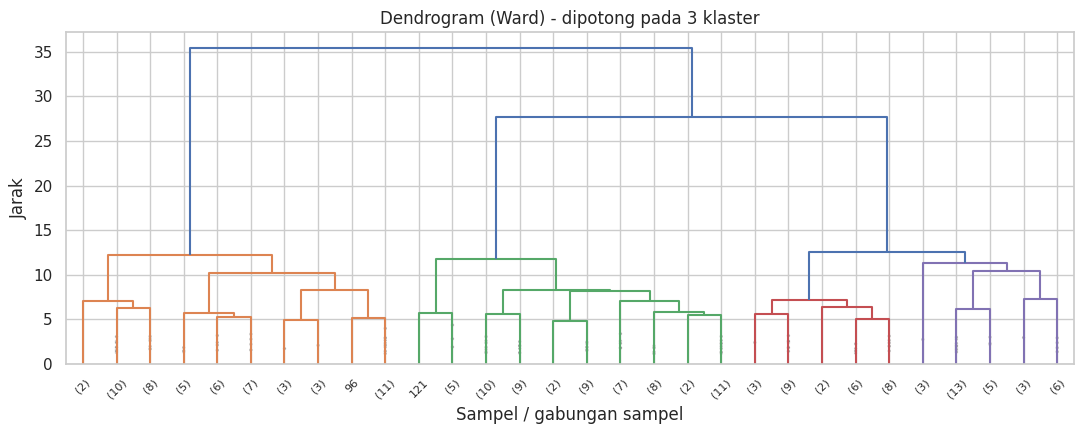

Hierarchical (Ward, K=3): ARI = 0.790, Silhouette = 0.277
K-Means (K=3)           : ARI = 0.897, Silhouette = 0.285


,proline,flavanoids,alcohol,od280/od315_of_diluted_wines,alcalinity_of_ash,proanthocyanins
klaster,,,,,,
0,510.17,2.05,12.25,2.80,20.06,1.62
1,619.06,0.82,13.13,1.70,21.24,1.15
2,1100.23,3.00,13.68,3.16,17.46,1.92


In [66]:
# Hierarchical clustering (Ward) sebagai pembanding K-Means
Z = linkage(Xs, method="ward")
fig, ax = plt.subplots(figsize=(11, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=Z[-3, 2], ax=ax,
           leaf_font_size=8, show_contracted=True)
ax.set_title("Dendrogram (Ward) - dipotong pada 3 klaster")
ax.set_xlabel("Sampel / gabungan sampel"); ax.set_ylabel("Jarak")
plt.tight_layout(); plt.savefig("../figures/12_dendrogram.png", dpi=150); plt.show()

agg = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(Xs)
print(f"Hierarchical (Ward, K=3): ARI = {adjusted_rand_score(y, agg.labels_):.3f}, "
      f"Silhouette = {silhouette_score(Xs, agg.labels_):.3f}")
print(f"K-Means (K=3)           : ARI = {adjusted_rand_score(y, lab):.3f}, "
      f"Silhouette = {silhouette_score(Xs, lab):.3f}")

# Profil kimia tiap klaster K-Means (skala asli)
prof = df[fitur].assign(klaster=lab).groupby("klaster")[top6].mean().round(2)
prof

**Interpretasi.** Hierarchical Ward (ARI 0,790) lebih rendah daripada K-Means (ARI 0,897) pada data ini, meski silhouette keduanya mirip. Profil rata-rata klaster (tabel di atas) memperlihatkan klaster yang mencerminkan kultivar: satu klaster ber-`proline` tinggi dan `flavanoids` tinggi (≈ Kultivar 0), satu klaster ber-`flavanoids` rendah (≈ Kultivar 2), dan satu klaster `alcohol` rendah (≈ Kultivar 1).

## Tahap 6 - Interpretasi

### 6.1 Fitur yang paling berpengaruh
Dua pendekatan dipakai: feature importance Random Forest (Gini) dan *permutation importance* pada model akhir (data uji), plus koefisien Logistic Regression.

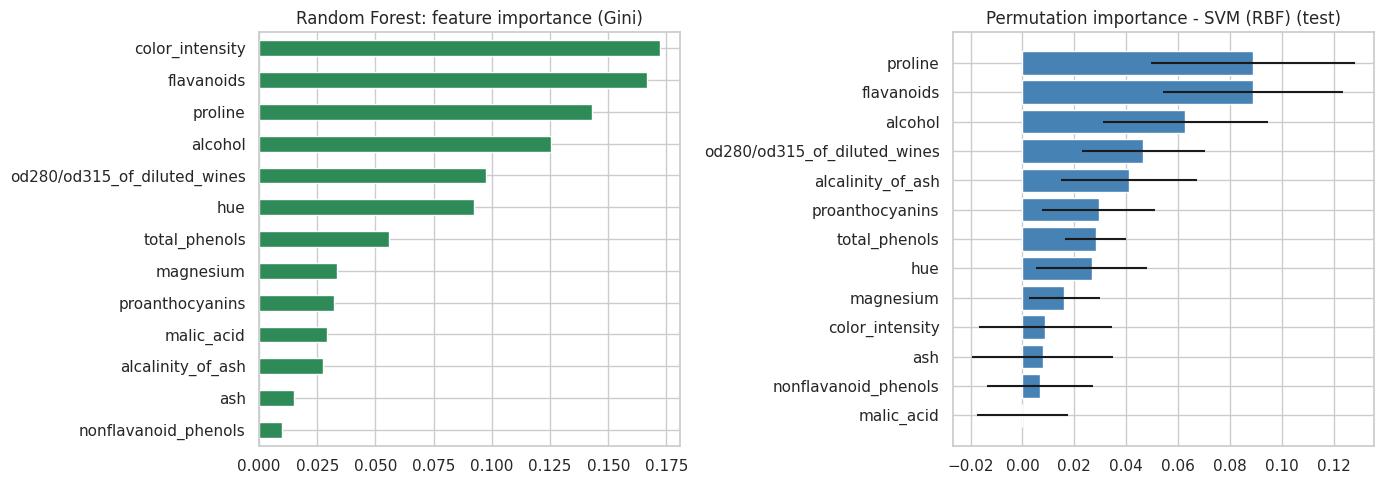

Top-5 Random Forest : {'color_intensity': 0.172, 'flavanoids': 0.167, 'proline': 0.143, 'alcohol': 0.125, 'od280/od315_of_diluted_wines': 0.097}
Top-5 Permutation   : {'proline': 0.089, 'flavanoids': 0.089, 'alcohol': 0.063, 'od280/od315_of_diluted_wines': 0.047, 'alcalinity_of_ash': 0.041}


In [67]:
# Interpretasi 1: Random Forest feature importance + Permutation importance (pada model terbaik)
rf = RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE).fit(X_train, y_train)
imp_rf = pd.Series(rf.feature_importances_, index=fitur).sort_values()

perm = permutation_importance(best_model, X_test, y_test, n_repeats=50,
                              random_state=RANDOM_STATE, scoring="accuracy")
imp_perm = pd.Series(perm.importances_mean, index=fitur)
imp_perm_std = pd.Series(perm.importances_std, index=fitur)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp_rf.plot.barh(ax=ax[0], color="seagreen"); ax[0].set_title("Random Forest: feature importance (Gini)")
o = imp_perm.sort_values().index
ax[1].barh(o, imp_perm[o], xerr=imp_perm_std[o], color="steelblue")
ax[1].set_title(f"Permutation importance - {model_terbaik} (test)")
plt.tight_layout(); plt.savefig("../figures/07_importance.png", dpi=150); plt.show()

print("Top-5 Random Forest :", imp_rf.sort_values(ascending=False).head(5).round(3).to_dict())
print("Top-5 Permutation   :", imp_perm.sort_values(ascending=False).head(5).round(3).to_dict())

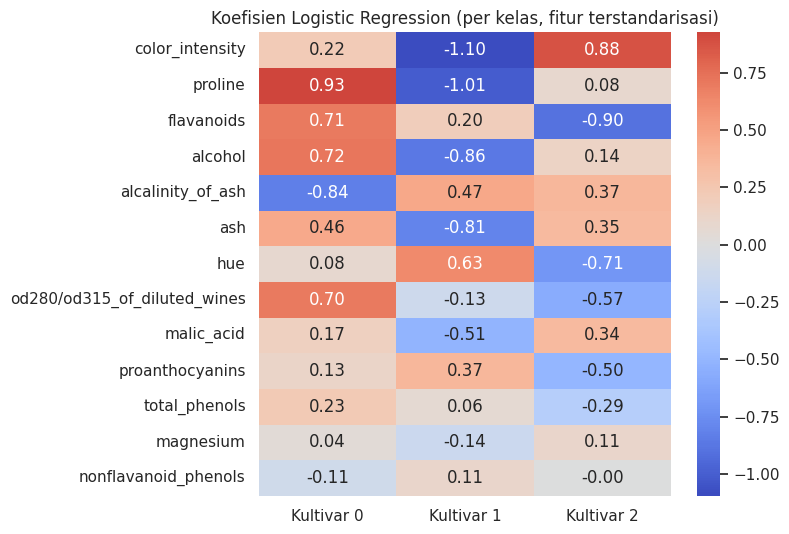

Rata-rata nilai fitur teratas per kultivar:


,proline,flavanoids,alcohol,od280/od315_of_diluted_wines,alcalinity_of_ash,proanthocyanins
kultivar,,,,,,
Kultivar 0,1115.71,2.98,13.74,3.16,17.04,1.90
Kultivar 1,519.51,2.08,12.28,2.79,20.24,1.63
Kultivar 2,629.90,0.78,13.15,1.68,21.42,1.15


In [68]:
# Interpretasi 2: koefisien Logistic Regression (fitur distandarisasi -> koefisien sebanding)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)).fit(X_train, y_train)
coef = pd.DataFrame(lr.named_steps["logisticregression"].coef_, columns=fitur, index=nama_kelas).T
coef["|rata-rata|"] = coef.abs().mean(axis=1)
coef = coef.sort_values("|rata-rata|", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(coef[nama_kelas], annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Koefisien Logistic Regression (per kelas, fitur terstandarisasi)")
plt.tight_layout(); plt.savefig("../figures/08_koefisien_logreg.png", dpi=150); plt.show()

# Rata-rata profil kimia per kultivar (skala asli) untuk 6 fitur teratas
top6 = imp_perm.sort_values(ascending=False).head(6).index.tolist()
print("Rata-rata nilai fitur teratas per kultivar:")
df.groupby("kultivar")[top6].mean().round(2)

**Temuan.** Fitur yang konsisten berada di peringkat atas pada berbagai metode: **`proline`, `flavanoids`, `color_intensity`, `alcohol`**, dan **`od280/od315_of_diluted_wines`**. Random Forest menempatkan `color_intensity` dan `flavanoids` teratas, sedangkan permutation importance menempatkan `proline` dan `flavanoids` teratas. Perbedaan urutan ini wajar, terutama karena fitur-fitur fenolik saling berkorelasi sehingga "pengaruh" terbagi di antara mereka. Maka kesimpulan yang aman adalah kelompok fitur ini penting, bukan peringkat pastinya.

Pola per kultivar (rata-rata skala asli): Kultivar 0 → `proline` tinggi (≈ 1115) dan `alcohol` tinggi (≈ 13,7); Kultivar 1 → `alcohol` rendah (≈ 12,3) dan `proline` rendah (≈ 520); Kultivar 2 → `flavanoids` sangat rendah (≈ 0,78) dan `od280/od315` rendah (≈ 1,7).

### 6.2 Apakah masuk akal secara biologis?
- **Flavonoid, fenol total, proantosianidin** adalah senyawa metabolit sekunder fenolik yang ada pada kulit dan biji anggur. Kadar dan komposisinya sangat dipengaruhi faktor genetik varietas, sehingga wajar bila menjadi pembeda kultivar (lihat Waterhouse, 2002).
- **`color_intensity` dan `hue`** terkait pigmen (antosianin dan turunannya), yang sifatnya khas varietas (jumlah dan profil antosianin).
- **`proline`** adalah asam amino paling melimpah pada buah anggur dan kadarnya bervariasi menurut varietas serta kondisi pematangan/lingkungan; kadar yang berbeda mencerminkan perbedaan metabolisme nitrogen antar-kultivar.
- **`alcohol`** mencerminkan kadar gula buah saat panen dan fermentasi, sehingga dipengaruhi varietas, tingkat kematangan, dan waktu panen.
- Hubungan `od280/od315` dengan `flavanoids` (r = 0,79) konsisten dengan fakta bahwa rasio tersebut merefleksikan kandungan fenol/protein pada sampel yang diencerkan.

> **Catatan referensi:** daftar pustaka di README memuat sumber dataset dan rujukan fenolik. Verifikasi detail bibliografinya sebelum dikutip pada laporan akhir.

## Tahap 7 - Diskusi dan Keterbatasan

**Keterbatasan data**
- Hanya **178 sampel**; data uji hanya 36 sampel sehingga estimasi performa memiliki ketidakpastian besar (satu kesalahan = 2,8 poin).
- Ketiga kultivar berasal dari **satu wilayah** dan dianalisis pada waktu tertentu: tidak mewakili variasi tahun panen (*vintage*), lokasi, atau praktik budidaya lain. Model belum tentu berlaku pada anggur dari daerah lain.
- Nama kultivar tidak tersedia pada versi sklearn (hanya kelas 0/1/2), sehingga interpretasi biologis tidak dapat dikaitkan ke varietas spesifik.
- Fitur saling berkorelasi (kelompok fenolik) sehingga importance/koefisien sulit dipisahkan per fitur.

**Risiko bias / leakage / overfitting**
- Leakage dicegah dengan Pipeline, split berstrata, dan data uji dipakai sekali. Skor CV hasil tuning cenderung sedikit optimistis (0,993 vs test 0,972 vs repeated CV 0,966).
- Performa tinggi sebagian besar karena dataset ini memang "mudah" (kelas terpisah baik), bukan bukti model akan sebaik itu pada data lapangan yang lebih berantakan.
- Standardisasi pada seluruh data untuk analisis unsupervised tidak memakai label sehingga tidak membocorkan informasi target.

**Yang tidak berhasil / catatan**
- Hierarchical Ward kurang cocok dengan kultivar dibanding K-Means (ARI 0,79 vs 0,90).
- Silhouette absolut rendah (0,285): klaster tidak terpisah sangat tegas; Kultivar 1 membaur dengan dua lainnya.
- Selisih antar-model supervised tidak signifikan secara praktis, jadi "model terbaik" tidak berbeda nyata.

**Saran pengembangan:** validasi pada data eksternal dari wilayah/vintage lain; coba *nested CV* untuk estimasi tuning yang tidak bias; uji model lain (gradient boosting, k-NN), seleksi fitur (mis. L1/RFE), serta uji signifikansi antar-model; gunakan data kimia berskala lebih besar.

## Kesimpulan
1. Profil kimia 13 variabel dapat membedakan tiga kultivar dengan sangat baik: SVM (RBF) tertune mencapai akurasi **0,972** dan AUC ≈ 1,0 pada data uji (repeated CV ≈ 0,966), jauh di atas baseline 0,40.
2. Secara unsupervised, **K = 3** didukung elbow & silhouette; K-Means menghasilkan klaster yang sangat cocok dengan kultivar (**ARI 0,897**).
3. Variabel paling berperan: **proline, flavanoids, color_intensity, alcohol, od280/od315**, konsisten dengan perbedaan fenolik, pigmen, dan metabolisme antar-kultivar.
4. Hasil perlu dibaca dengan hati-hati karena data kecil dan berasal dari satu wilayah.